# 神经网络均值—方差组合优化：完整实验

**Issue #760 · MSML610 Fall2026 · bcai1-stack**

研究三个问题：
1. 在相同样本外日期和交易成本下，学习方法能否超过简单配置？
2. 直接预测最优权重的网络，是否能以可接受的误差换取速度？
3. 决策导向训练与预测后优化的差异，是否可能由简单均值收缩解释？

运行顺序：安装依赖 → 数据 → 两类约束下的近似优化器 → 三个随机种子的滚动回测 → 图表与解释。CPU 完整运行通常需要数分钟，具体时间以本机输出为准。

[实验说明](mvo.example.md) · [API Notebook](mvo.API.ipynb) · [研究来源](docs/related_projects.md)。

In [1]:
# 在当前 Notebook 的 Python 环境安装项目额外依赖；保留模板依赖文件。
%pip install -q scikit-learn==1.8.0 torch==2.8.0 cvxpy==1.9.2 cvxpylayers==1.2.0

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import torch
from IPython.display import Image, display
from mvo.data import download_french, validate_returns
from mvo.amortized import run_experiment
from mvo.backtest import Config, run_backtest

torch.set_num_threads(1)
ROOT = Path.cwd()
assert (ROOT / "mvo").is_dir(), "请从项目目录运行 Notebook。"
SEEDS = [7, 11, 19]
OUTPUT = ROOT / "results"
OUTPUT.mkdir(exist_ok=True)

## 1. 数据来源和边界

使用 Kenneth French 十行业价值加权日收益，固定为 2010—2025 年。行业组合是研究收益序列，不是十只可直接交易的 ETF。数据供应方可能修订历史收益，因此记录下载内容 SHA-256。

初次运行下载数据，后续校验缓存的哈希。下载失败会报错，不会自动改用模拟数据。数据不足、重复日期、缺失值会被拒绝。

[French 数据库](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html)

In [3]:
data_path = ROOT / "data/french10.csv"
if not data_path.exists():
    returns = download_french(data_path)
else:
    provenance = json.loads(data_path.with_suffix(".json").read_text())
    assert hashlib.sha256(data_path.read_bytes()).hexdigest() == provenance["csv_sha256"]
    returns = validate_returns(pd.read_csv(data_path, index_col=0, parse_dates=True))
provenance = json.loads(data_path.with_suffix(".json").read_text())
print(provenance)
display(returns.head())
display(pd.DataFrame({"annual_mean": returns.mean() * 252,
                      "annual_volatility": returns.std() * np.sqrt(252)}))

{'source': 'https://mba.tuck.dartmouth.edu/pages/faculty/Ken.French/ftp/10_Industry_Portfolios_daily_CSV.zip', 'start': '2010-01-04', 'end': '2025-12-31', 'rows': 4024, 'archive_sha256': '4c79bad80b6f4eee9d08e649ce223d1c51aadd65043b65baca50b54981d38d25', 'csv_sha256': 'ee1cb6e7a2c1b7fd20d042223bcceb25211f6283edd705148576ac10cf2f5270'}


,NoDur,Durbl,Manuf,Enrgy,HiTec,Telcm,Shops,Hlth,Utils,Other
date,,,,,,,,,,
2010-01-04,0.0098,0.0235,0.0224,0.0300,0.0159,0.0147,0.0080,0.0131,0.0066,0.0198
2010-01-05,0.0031,0.0257,0.0041,0.0078,0.0000,0.0011,-0.0013,-0.0060,-0.0084,0.0091
2010-01-06,0.0022,0.0123,0.0055,0.0094,-0.0069,-0.0103,-0.0003,0.0053,0.0054,0.0022
2010-01-07,0.0004,0.0144,0.0031,-0.0033,-0.0035,-0.0017,0.0063,0.0013,-0.0045,0.0168
2010-01-08,-0.0048,0.0055,0.0073,0.0045,0.0076,-0.0015,-0.0001,0.0025,-0.0005,0.0029


,annual_mean,annual_volatility
NoDur,0.100631,0.144492
Durbl,0.217112,0.340550
Manuf,0.129726,0.188369
Enrgy,0.097306,0.276652
HiTec,0.196077,0.218011
Telcm,0.102347,0.169985
Shops,0.157168,0.173873
Hlth,0.134348,0.168044
Utils,0.112329,0.171336
Other,0.140873,0.203343


## 2. 实验 A：近似优化器的速度与误差

独立生成正定协方差与年化均值，训练 64×64 MLP；Softmax 保证非负满仓。带换手上限时，把上期权重加入输入，并沿“上期权重→网络建议权重”的线段缩放，保证 L1 换手不超过 0.4。训练标签、网络输出和精确求解器使用相同约束。

每个设置使用 512 个训练实例和 128 个未见测试实例。分别计量：目标差距、约束误差、单实例推理时间、预热求解器时间、批量吞吐量、标签生成与训练时间。时间收支平衡点不包含近似误差成本。人工生成的实例用于受控计算实验，不代表实际市场分布。

In [4]:
amortized = {}
for label, limit in [("long_only", None), ("turnover_0.4", 0.4)]:
    amortized[label] = run_experiment(OUTPUT / label, seed=7, turnover_limit=limit)
columns = ["objective_gap_mean", "objective_gap_p95", "weight_rmse",
           "nn_single_median_ms", "solver_single_median_ms", "break_even_instances",
           "maximum_budget_error", "maximum_turnover"]
display(pd.DataFrame(amortized).T[columns])

,objective_gap_mean,objective_gap_p95,weight_rmse,nn_single_median_ms,solver_single_median_ms,break_even_instances,maximum_budget_error,maximum_turnover
long_only,0.039275,0.10416,0.133604,0.151,0.503208,1892,0.0,1.837617
turnover_0.4,0.019618,0.040228,0.056225,0.181771,0.554834,1102,0.0,0.4


## 3. 实验 B：严格按时间滚动评估

每折使用 60 个训练期、12 个验证期、12 个测试期；每期 21 个交易日，历史窗口 126 日。特征包含过去 5/21/63 日均值和历史波动率，协方差使用 Ledoit–Wolf 收缩估计。标准化只拟合训练集，验证集选择轮次，测试集只评价。

比较六种策略：等权、最小方差、历史均值 MVO、均值缩小到 25% 的 MVO、预测 MSE 训练、决策效用训练。两个学习方法使用相同网络和输入。全部策略按买入或卖出一美元收费 10 bps，持有期间权重随收益漂移，跨折保留持仓，初始现金转满仓也扣费。

训练效用使用毛收益、期内方差；最终评价使用扣费后的完整测试收益。因此训练损失只是评价目标的代理。这里回测不施加换手上限，换手约束的计算实验单独在实验 A 中评价。

In [5]:
reports = {}
for seed in SEEDS:
    config = Config(seed=seed, epochs=15)
    reports[str(seed)] = run_backtest(returns, OUTPUT / f"french_seed{seed}", config,
                                    source=provenance["source"])
metrics = pd.concat({seed: pd.DataFrame(report["metrics"]).T
                     for seed, report in reports.items()}, names=["seed", "strategy"])
display(metrics.groupby("strategy").mean().round(4))

Training fold 1, test 2016-07-07


Training fold 2, test 2017-07-07


Training fold 3, test 2018-07-09


Training fold 4, test 2019-07-10


Training fold 5, test 2020-07-09


Training fold 6, test 2021-07-09


... (21 outputs left out)

Training fold 8, test 2023-07-12


Training fold 9, test 2024-07-12


Training fold 10, test 2025-07-16


,cagr,annual_volatility,sharpe_rf_zero,max_drawdown,annual_utility,annual_turnover,maximum_target_weight
strategy,,,,,,,
decision_focused,0.0802,0.1661,0.5472,-0.3265,-0.0470,13.4624,1.0000
equal_weight,0.1346,0.1770,0.8029,-0.3657,-0.0145,0.4718,0.1000
historical_mvo,0.0665,0.2117,0.4105,-0.3851,-0.1373,10.5233,1.0000
minimum_variance,0.0711,0.1464,0.5425,-0.2937,-0.0278,2.9923,0.7695
predict_then_optimize,0.0666,0.1613,0.4809,-0.3290,-0.0526,12.8362,1.0000
shrunk_mean_mvo,0.0648,0.1612,0.4704,-0.3245,-0.0541,7.0423,0.7922


## 4. 样本外净值和回撤

下面固定展示 seed=7，不根据结果挑选最优种子。上表汇总所有三个预先列出的种子。Sharpe 使用零无风险利率；最大回撤包含初始资金；最大权重指调仓时的目标权重。

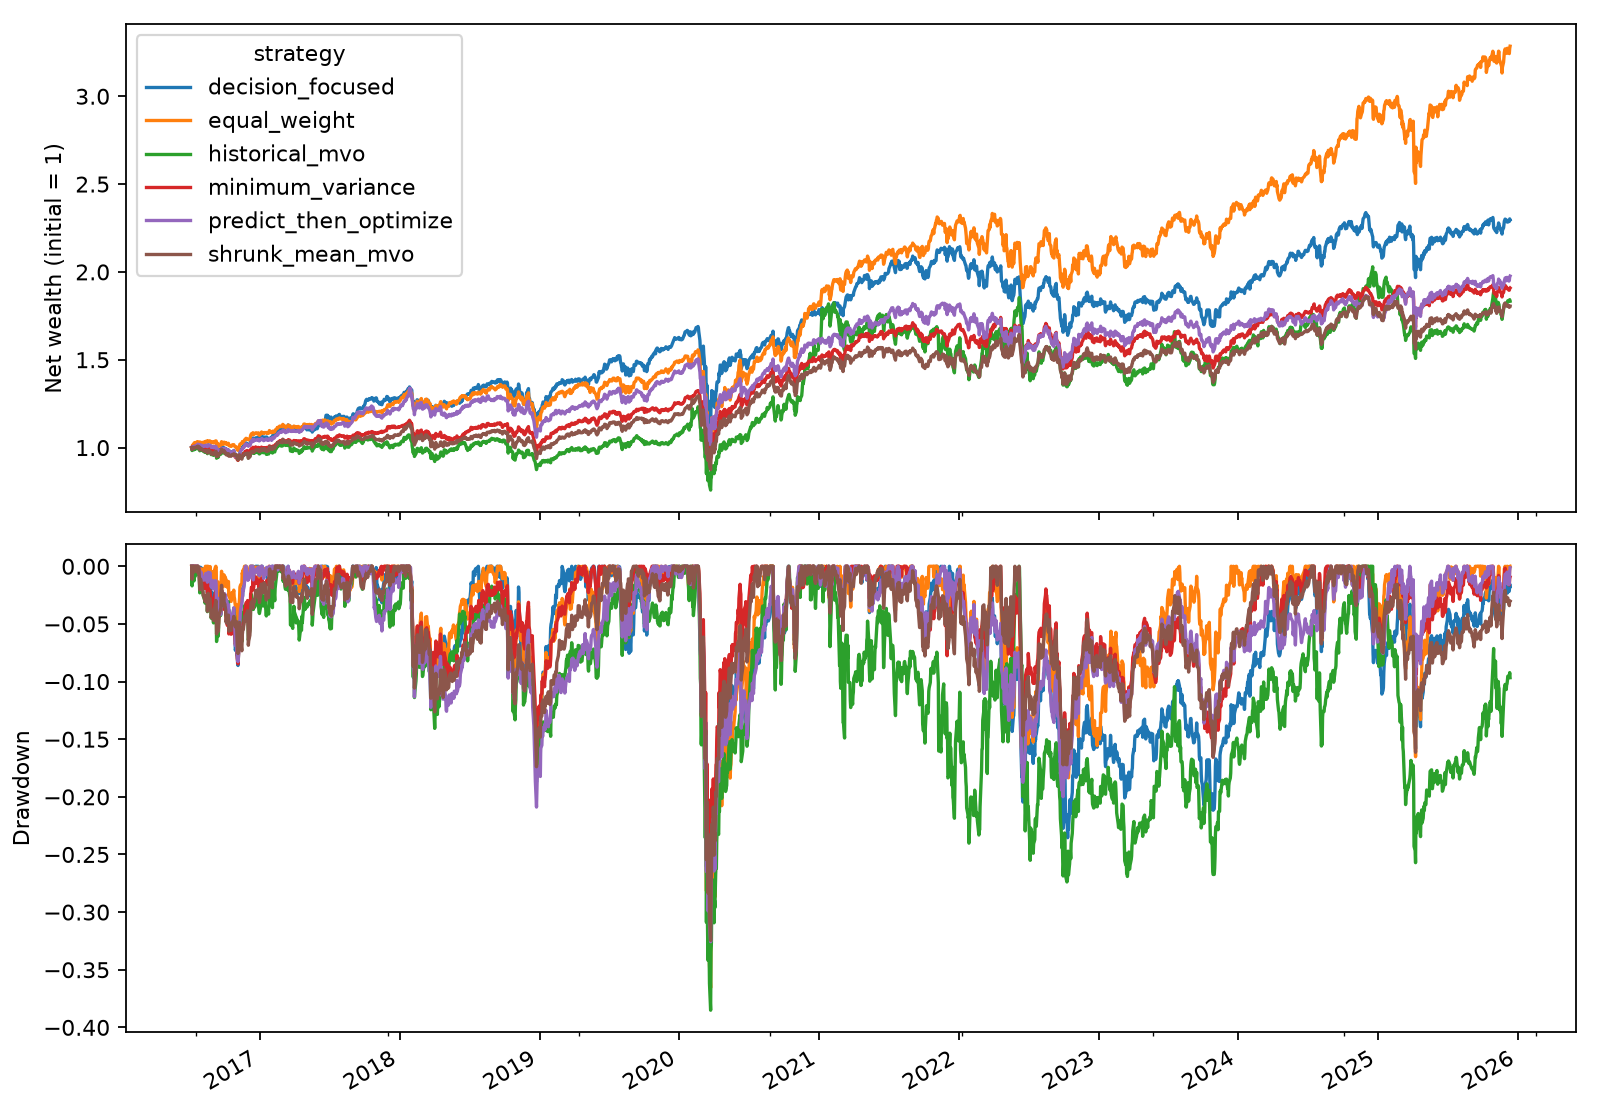

annual_utility  sharpe_rf_zero  annual_turnover  \
seed strategy                                                                 
7    decision_focused              -0.0403          0.6073          14.7197   
     equal_weight                  -0.0145          0.8029           0.4718   
     historical_mvo                -0.1373          0.4105          10.5233   
     minimum_variance              -0.0278          0.5425           2.9923   
     predict_then_optimize         -0.0434          0.5316          13.5418   
     shrunk_mean_mvo               -0.0541          0.4704           7.0423   
11   decision_focused              -0.0461          0.5156          12.7914   
     equal_weight                  -0.0145          0.8029           0.4718   
     historical_mvo                -0.1373          0.4105          10.5233   
     minimum_variance              -0.0278          0.5425           2.9923   
     predict_then_optimize         -0.0519          0.4656          12.4726   
     shrunk_mean_mvo               -0.0541          0.4704           7.0423   
19   decision_focused              -0.0547          0.5187          12.8762   
     equal_weight                  -0.0145          0.8029           0.4718   
     historical_mvo                -0.1373          0.4105          10.5233   
     minimum_variance              -0.0278          0.5425           2.9923   
     predict_then_optimize         -0.0626          0.4453          12.4943   
     shrunk_mean_mvo               -0.0541          0.4704           7.0423   

                            maximum_target_weight  
seed strategy                                      
7    decision_focused                      1.0000  
     equal_weight                          0.1000  
     historical_mvo                        1.0000  
     minimum_variance                      0.7695  
     predict_then_optimize                 1.0000  
     shrunk_mean_mvo                       0.7922  
11   decision_focused                      1.0000  
     equal_weight                          0.1000  
     historical_mvo                        1.0000  
     minimum_variance                      0.7695  
     predict_then_optimize                 1.0000  
     shrunk_mean_mvo                       0.7922  
19   decision_focused                      1.0000  
     equal_weight                          0.1000  
     historical_mvo                        1.0000  
     minimum_variance                      0.7695  
     predict_then_optimize                 1.0000  
     shrunk_mean_mvo                       0.7922

In [6]:
display(Image(filename=str(OUTPUT / "french_seed7/backtest.png")))
display(metrics[["annual_utility", "sharpe_rf_zero", "annual_turnover",
                 "maximum_target_weight"]].round(4))

## 5. 不确定性与结果解释

配对循环区块 bootstrap 使用相同日期和 21 日区块。区间跨零意味着此检查不能区分效用差异；它不能修复非平稳性、数据选择偏差或多次试验的选择偏差。不同随机种子也共享同一市场历史，不能视为独立市场样本。

若神经网络未超过等权、最小方差或简单收缩，应该如实报告。这个研究的成功标准是公平、可复现的比较，而不是保证某个模型取胜。

In [7]:
intervals = pd.DataFrame(reports["7"]["decision_focused_minus_baseline_utility_ci"]).T
display(intervals)
for baseline, interval in intervals.iterrows():
    if interval.lower_95 > 0:
        conclusion = "本次区间完全高于零"
    elif interval.upper_95 < 0:
        conclusion = "本次区间完全低于零"
    else:
        conclusion = "本次区间跨零，优势不确定"
    print(f"决策导向 − {baseline}：{conclusion}")

,lower_95,upper_95,block_days,draws
equal_weight,-0.076532,0.027484,21.0,1000.0
minimum_variance,-0.059808,0.033623,21.0,1000.0
predict_then_optimize,-0.033007,0.041703,21.0,1000.0


决策导向 − equal_weight：本次区间跨零，优势不确定
决策导向 − minimum_variance：本次区间跨零，优势不确定
决策导向 − predict_then_optimize：本次区间跨零，优势不确定


## 6. 保存可追溯的结果

完整收益、权重、模型、图片保存在被 Git 忽略的 `results/`；提交的结果快照保存输入哈希、配置、每折日期、各模型指标和运行时间。

局限：风险偏好和网络结构为固定设置；缺少独立的最终保留时期；回测按行业组合收益近似可交易组合；交易成本使用小费率近似；没有整数手数/持仓数量约束；历史研究结论不保证未来收益。

In [8]:
snapshot = {"data": provenance, "amortized": amortized, "backtests": reports}
(ROOT / "docs/experiment_snapshot.json").write_text(json.dumps(snapshot, indent=2) + "\n")
metrics.to_csv(ROOT / "docs/strategy_metrics.csv")
from mvo.reporting import write_report
write_report(snapshot, ROOT)
print("完整实验已完成。请结合 docs/experiment_report.md 阅读结果。")

完整实验已完成。请结合 docs/experiment_report.md 阅读结果。
